# 01: Data Audit

Full audit of `train.csv`, `test.csv` and `clientes.csv` before any modelling.

1. Overview
2. Missing values
3. Duplicates
4. Invalid values and consistency rules
5. Targets
6. Numeric features
7. Categorical features
8. Time
9. `random_noise`
10. `clientes.csv`
11. Train vs test
12. Conclusions and cleaning plan

Nothing is modified here — this notebook only finds the problems. The fixes go into the pipeline (`src/`) so they are applied identically to train, test and new purchases.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
import yaml

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

with open("../config.yaml", "r") as f:
    CONFIG = yaml.safe_load(f)

with open("../diagnosis.yaml", "r") as f:
    diagnosis = yaml.safe_load(f)





train = pd.read_csv(f"../{CONFIG['paths']['train']}")
test = pd.read_csv(f"../{CONFIG['paths']['test']}")
clients = pd.read_csv(f"../{CONFIG['paths']['clients']}")

CLF_TARGET, REG_TARGET = CONFIG["targets"]["classification"], CONFIG["targets"]["regression"]

ID_COLS = CONFIG["id_cols"]
CAT_COLS = ["payment_type", "salesperson", "commercial_zone",
            "transport_method", "warehouse", "document_series"]
NUM_COLS = [c for c in test.columns if c not in ID_COLS + CAT_COLS + ["purchase_date"]]

print(f"train {train.shape}  test {test.shape}  clientes {clients.shape}")

train (6534, 40)  test (986, 38)  clientes (1143, 13)


## 1. Overview

In [20]:
expected_types = {
    "Total a Pagar": "continuous",
    "Total Bruto": "continuous",
    "Total Liquido": "continuous",
    "Total Imp_": "continuous",
    "Total Portes": "continuous",
    "Total Desc_ Global": "continuous",
    "Total Desc_ Linha": "continuous",
    "Custo": "continuous",
    "N_ Detalhes": "count",
    "invoice_count_current_purchase": "count",
    "repeat_purchase_90d": "binary",
    "spend_next_90d": "continuous",
    "days_since_previous_purchase": "integer (days)",
    "customer_tenure_days": "integer (days)",
    "prior_purchase_count": "count",
    "prior_total_spend": "continuous",
    "prior_mean_purchase_value": "continuous",
    "prior_std_purchase_value": "continuous",
    "prior_min_purchase_value": "continuous",
    "prior_max_purchase_value": "continuous",
    "prior_mean_gap_days": "continuous (days)",
    "prior_std_gap_days": "continuous (days)",
    "purchase_count_30d": "count",
    "spend_30d": "continuous",
    "purchase_count_90d": "count",
    "spend_90d": "continuous",
    "purchase_count_180d": "count",
    "spend_180d": "continuous",
    "purchase_count_365d": "count",
    "spend_365d": "continuous",
    "customer_id": "identifier",
    "payment_type": "nominal categorical",
    "salesperson": "nominal categorical",
    "commercial_zone": "nominal categorical",
    "transport_method": "nominal categorical",
    "warehouse": "nominal categorical",
    "document_series": "nominal categorical",
    "purchase_date": "date",
    "ID": "identifier",
    "random_noise": "continuous",
}

overview = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "expected_type": pd.Series(expected_types).reindex(train.columns),
    "n_unique": train.nunique(),
    "missing_train": train.isna().sum(),
    "missing_test": test.isna().sum().reindex(train.columns),
})

display(overview)

,dtype,expected_type,n_unique,missing_train,missing_test
Total a Pagar,float64,continuous,6122,65,0.00
Total Bruto,float64,continuous,6040,65,0.00
Total Liquido,float64,continuous,6095,65,0.00
Total Imp_,float64,continuous,5412,65,0.00
Total Portes,float64,continuous,215,65,0.00
Total Desc_ Global,float64,continuous,109,65,0.00
Total Desc_ Linha,float64,continuous,3520,65,0.00
Custo,float64,continuous,5758,65,0.00
N_ Detalhes,float64,count,171,65,0.00
invoice_count_current_purchase,float64,count,5,65,0.00


In [21]:
print("Columns only in train:", sorted(set(train.columns) - set(test.columns)))
print("ID unique in train:", train["ID"].is_unique, "| in test:", test["ID"].is_unique,
      "| overlap:", len(set(train["ID"]) & set(test["ID"])))
print("Rows per customer in train:", train["customer_id"].value_counts().describe().round(1).to_dict())

Columns only in train: ['repeat_purchase_90d', 'spend_next_90d']
ID unique in train: True | in test: True | overlap: 0
Rows per customer in train: {'count': 610.0, 'mean': 10.7, 'std': 20.0, 'min': 1.0, '25%': 1.0, '50%': 4.0, '75%': 12.0, 'max': 277.0}


In [15]:
train[NUM_COLS + [CLF_TARGET, REG_TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,"6,469.00",925.56,"1,335.00",0.93,188.92,476.74,"1,087.67","22,297.21"
Total Bruto,"6,469.00",886.15,"1,327.64",0.83,175.74,445.74,"1,036.70","21,578.28"
Total Liquido,"6,469.00",773.34,"1,136.36",0.76,154.38,389.91,903.37,"18,127.81"
Total Imp_,"6,469.00",152.22,225.26,0.00,29.93,79.74,184.84,"4,169.40"
Total Portes,"6,469.00",1.15,5.84,0.00,0.00,0.00,0.00,181.06
Total Desc_ Global,"6,469.00",0.35,5.12,0.00,0.00,0.00,0.00,218.49
Total Desc_ Linha,"6,469.00",112.47,289.99,0.00,0.00,13.13,92.28,"4,103.44"
Custo,"6,469.00",328.17,519.51,0.00,49.05,152.54,396.06,"7,427.40"
N_ Detalhes,"6,469.00",21.52,27.71,1.00,4.00,11.00,29.00,423.00
invoice_count_current_purchase,"6,469.00",1.07,0.31,1.00,1.00,1.00,1.00,5.00


**Observations**
- `purchase_date` is stored as text and must be parsed.
- Some `describe()` values are impossible at first glance: `prior_mean_purchase_value` and `spend_365d` reach **1e9**, and `days_since_previous_purchase` / `prior_mean_gap_days` have a **negative minimum (-4)**. Investigated in section 4.
- Customers appear many times (one row per purchase occasion), so rows of the same customer are not independent.

## 2. Missing values

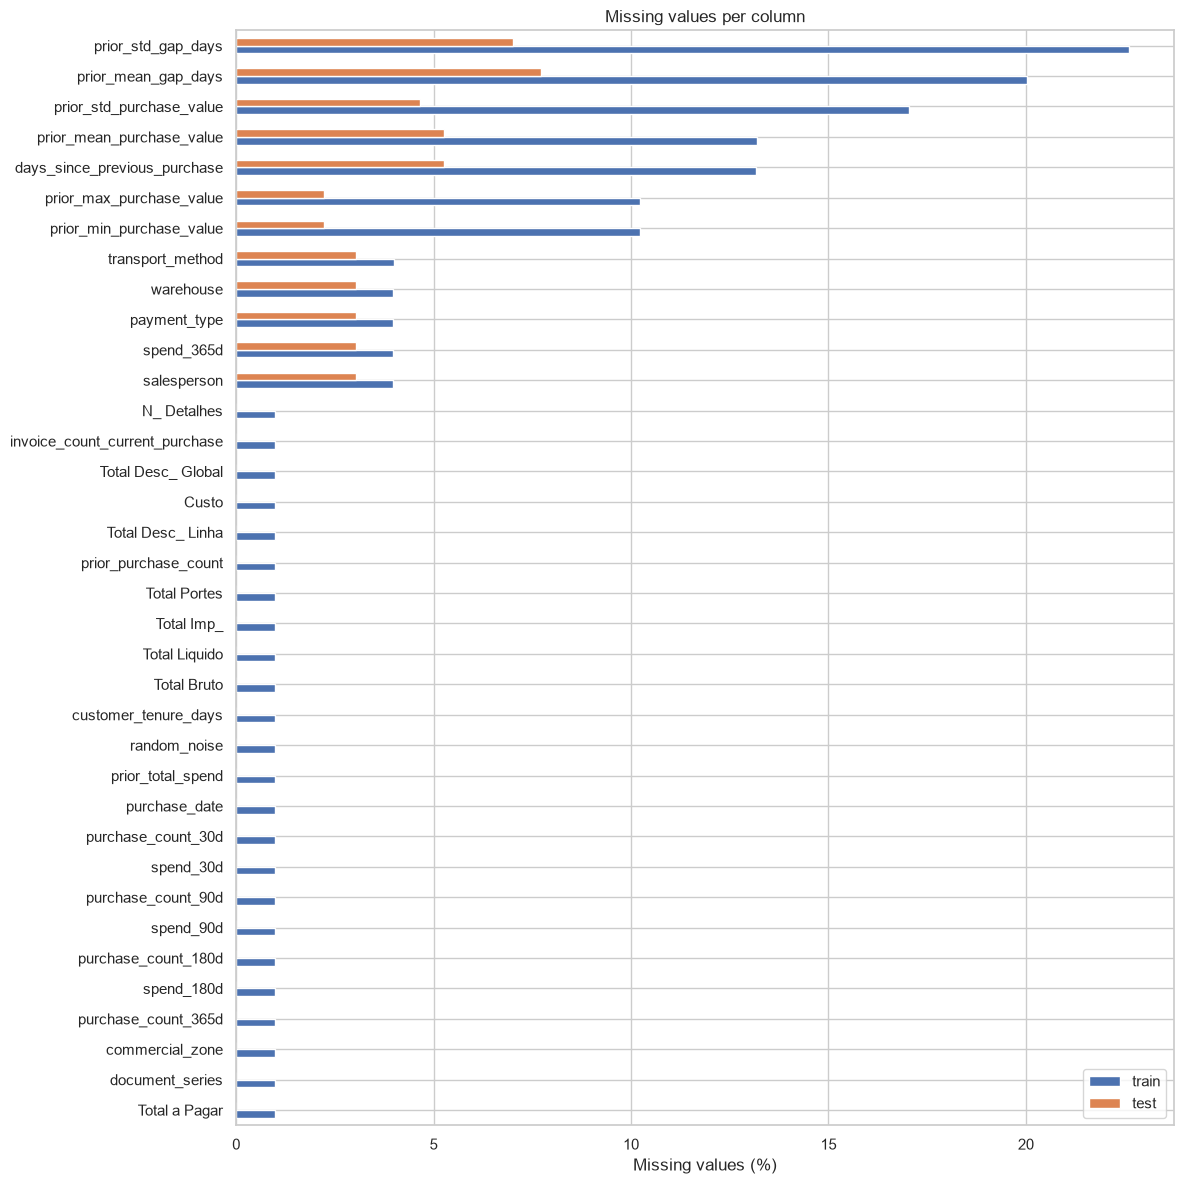

In [28]:
train_clean = train.copy()
test_clean = test.copy()

train_clean = train_clean.drop(columns=ID_COLS + [CLF_TARGET, REG_TARGET])
test_clean = test_clean[train_clean.columns]

missing = pd.DataFrame({
    "train": train_clean.isna().mean() * 100,
    "test": test_clean.isna().mean() * 100,
}).sort_values("train")

ax = missing.plot.barh(figsize=(12, 12))
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
ax.set_title("Missing values per column")
plt.tight_layout()
plt.show()

There are three different kinds of missing values. They need different treatment, so they are separated below.

### 2.1 Fully empty rows

In [30]:
feature_cols = [c for c in train.columns if c not in ID_COLS + [CLF_TARGET, REG_TARGET]]
empty_rows = train[feature_cols].isna().all(axis=1)
print(f"Rows with every feature missing: {empty_rows.sum()} ({empty_rows.mean():.1%})")
print("Classification target counts among training rows with all features missing:", train.loc[empty_rows, CLF_TARGET].value_counts().to_dict())
print("Empty rows in test:", test[[c for c in feature_cols if c in test]].isna().all(axis=1).sum())

Rows with every feature missing: 65 (1.0%)
Classification target counts among training rows with all features missing: {1: 33, 0: 32}
Empty rows in test: 0


### 2.2 Structural missing values (customer has no history yet)

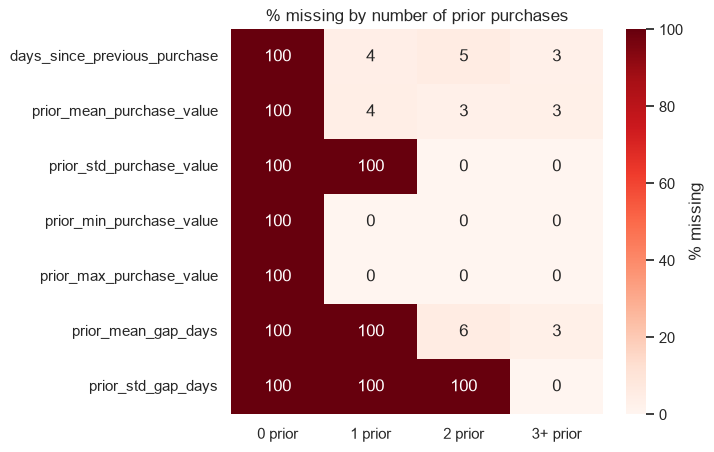

In [32]:
non_empty = train[~empty_rows]
history_cols = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                "prior_min_purchase_value", "prior_max_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]

structural = (non_empty.groupby(non_empty["prior_purchase_count"].clip(upper=3))[history_cols]
              .apply(lambda g: g.isna().mean() * 100))
structural.index = ["0 prior", "1 prior", "2 prior", "3+ prior"]
plt.figure(figsize=(6, 5))
sns.heatmap(structural.T, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("% missing by number of prior purchases")
plt.show()

With 0 prior purchases every history statistic is missing; with 1 prior purchase the purchase-value std and both gap statistics are missing (one value has no std and no gap); with 2 prior purchases `prior_std_gap_days` is missing (one gap has no std). These are **not errors**: the value does not exist. Imputing them with a mean would be wrong — better to fill with a neutral value and keep an indicator (e.g. `is_first_purchase`).

### 2.3 Random missing values (injected errors)
The first print shows missing-value counts per column. For the two purchase-history columns, it counts only rows with a prior purchase.

The second print counts rows missing two or more categorical values. Both prints exclude rows where every feature is missing.

In [8]:
has_history = non_empty["prior_purchase_count"] > 0
random_missing = pd.Series({
    "days_since_previous_purchase (with history)": non_empty.loc[has_history, "days_since_previous_purchase"].isna().sum(),
    "prior_mean_purchase_value (with history)": non_empty.loc[has_history, "prior_mean_purchase_value"].isna().sum(),
    "spend_365d": non_empty["spend_365d"].isna().sum(),
    **{c: non_empty[c].isna().sum() for c in CAT_COLS},
})
print(random_missing.to_string())
print("\nRows with >1 of these categoricals missing at once:",
      (non_empty[CAT_COLS].isna().sum(axis=1) > 1).sum())

days_since_previous_purchase (with history)    193
prior_mean_purchase_value (with history)       194
spend_365d                                     195
payment_type                                   195
salesperson                                    194
commercial_zone                                  0
transport_method                               196
warehouse                                      195
document_series                                  0

Rows with >1 of these categoricals missing at once: 31


In [9]:
# Does missingness carry information about the target?
rows = []
for c in ["days_since_previous_purchase", "spend_365d", "payment_type", "salesperson", "transport_method", "warehouse"]:
    m = non_empty[c].isna()
    if c == "days_since_previous_purchase":
        m = m & has_history
    rows.append({"column": c, "n_missing": m.sum(),
                 "target_rate_missing": non_empty.loc[m, CLF_TARGET].mean(),
                 "target_rate_present": non_empty.loc[~m, CLF_TARGET].mean()})
pd.DataFrame(rows)

,column,n_missing,target_rate_missing,target_rate_present
0,days_since_previous_purchase,193,0.57,0.56
1,spend_365d,195,0.56,0.56
2,payment_type,195,0.56,0.56
3,salesperson,194,0.60,0.56
4,transport_method,196,0.55,0.56
5,warehouse,195,0.64,0.56


~195 values (≈3%) are missing in each of these columns, scattered independently across rows and with roughly the same target rate as present values → they look **missing completely at random**. Some can be recomputed exactly (`prior_mean_purchase_value = prior_total_spend / prior_purchase_count`); the rest need imputation inside the pipeline. The same pattern exists in test, so the pipeline must handle it at prediction time too.

## 3. Duplicates

In [10]:
print("Exact duplicate rows:", train.duplicated().sum())
dup = train.drop(columns="ID").duplicated(keep=False)
print("Duplicates ignoring ID:", train.drop(columns="ID").duplicated().sum())
print("...of which are empty rows:", (dup & empty_rows).sum(), "of", dup.sum())
print("Same customer + same date (non-empty):",
      non_empty.duplicated(["customer_id", "purchase_date"]).sum())
print("Duplicates in test ignoring ID:", test.drop(columns="ID").duplicated().sum())

Exact duplicate rows: 0
Duplicates ignoring ID: 10
...of which are empty rows: 16 of 16
Same customer + same date (non-empty): 0
Duplicates in test ignoring ID: 0


The only duplicates are among the empty rows (same customer, everything else missing). Once the empty rows are dropped there are no duplicate purchase occasions.

## 4. Invalid values and consistency rules

Every column comes with logical rules (a 30-day count cannot exceed a 90-day count, a maximum cannot exceed a total, ...). Each rule is checked on train and test.

In [45]:
import pandas as pd


def check_rules(df, config):
    counts = {}

    for col, bounds in config.get("ranges", {}).items():
        if col not in df.columns:
            continue

        minimum = bounds.get("min")
        maximum = bounds.get("max")

        if minimum is not None:
            counts[f"{col}_below_min"] = df[col].lt(minimum).sum()
        if maximum is not None:
            counts[f"{col}_above_max"] = df[col].gt(maximum).sum()

    for col, rule in config.get("sentinels", {}).items():
        if col not in df.columns:
            continue

        counts[f"{col}_sentinel"] = df[col].ge(rule["min_inclusive"]).sum()

    for name, rule in config.get("consistency", {}).items():
        rows = df
        where = rule.get("where")

        if where:
            eligible = df.eval(where, engine="python").fillna(False)
            rows = df.loc[eligible]

        if rows.empty:
            counts[name] = 0
            continue

        violations = rows.eval(rule["violation"], engine="python")
        counts[name] = violations.sum()

    return pd.Series(counts, dtype="Int64")


def highlight_violation(count):
    if pd.notna(count) and count > 0:
        return "background-color: #871818; color: white"
    return ""


rules = pd.DataFrame({
    "train": check_rules(train, diagnosis),
    "test": check_rules(test, diagnosis),
}).astype("Int64")

styled_rules = (
    rules.style
    .format(precision=0, na_rep="—")
    .map(highlight_violation, subset=["train", "test"])
)

display(styled_rules)

,train,test
Custo_below_min,0,0
N_ Detalhes_below_min,0,0
Total Bruto_below_min,0,0
Total Desc_ Global_below_min,0,0
Total Desc_ Linha_below_min,0,0
Total Imp__below_min,0,0
Total Liquido_below_min,0,0
Total Portes_below_min,0,0
Total a Pagar_below_min,0,0
customer_tenure_days_below_min,0,0


### 4.1 The -4 sentinel

In [12]:
for c in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    print(c, "negative values:", sorted(train.loc[train[c] < 0, c].unique()),
          "| rows:", (train[c] < 0).sum())
print("Rows where both are -4:",
      ((train["days_since_previous_purchase"] < 0) & (train["prior_mean_gap_days"] < 0)).sum())

days_since_previous_purchase negative values: [np.float64(-4.0)] | rows: 16
prior_mean_gap_days negative values: [np.float64(-4.0)] | rows: 16
Rows where both are -4: 0


A gap in days cannot be negative and the only negative value is exactly **-4** → a placeholder code, not a measurement. Treat as missing.

### 4.2 Sign flips

In [13]:
neg = train[train["prior_mean_purchase_value"] < 0]
print("prior_mean < 0: |value| == total/count ->",
      np.allclose(neg["prior_mean_purchase_value"].abs(), neg["prior_total_spend"] / neg["prior_purchase_count"]))
neg = train[train["spend_365d"] < 0]
print("spend_365d < 0: |value| >= spend_180d ->", (neg["spend_365d"].abs() >= neg["spend_180d"]).all())

prior_mean < 0: |value| == total/count -> True
spend_365d < 0: |value| >= spend_180d -> True


The negative values are the correct values with the sign flipped (absolute value matches the other columns exactly). Fix: take the absolute value.

### 4.3 Inflated values

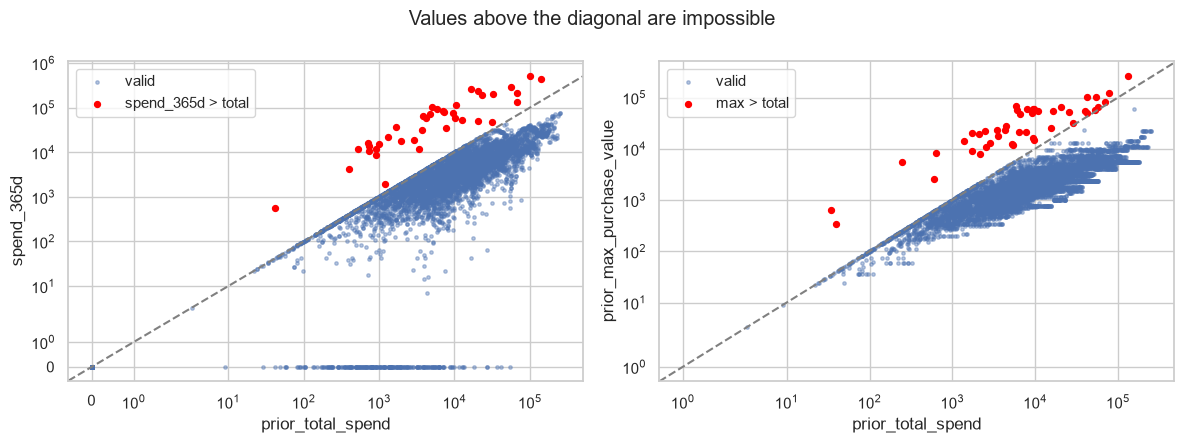

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
valid = train[train["spend_365d"].between(0, 1e8)]
bad = valid["spend_365d"] > valid["prior_total_spend"] + 0.01
axes[0].scatter(valid.loc[~bad, "prior_total_spend"], valid.loc[~bad, "spend_365d"], s=6, alpha=0.4, label="valid")
axes[0].scatter(valid.loc[bad, "prior_total_spend"], valid.loc[bad, "spend_365d"], s=18, c="red", label="spend_365d > total")
axes[0].set(xscale="symlog", yscale="symlog", xlabel="prior_total_spend", ylabel="spend_365d")
axes[0].axline((1, 1), (10, 10), color="grey", ls="--")
axes[0].legend()

bad = train["prior_max_purchase_value"] > train["prior_total_spend"] + 0.01
axes[1].scatter(train.loc[~bad, "prior_total_spend"], train.loc[~bad, "prior_max_purchase_value"], s=6, alpha=0.4, label="valid")
axes[1].scatter(train.loc[bad, "prior_total_spend"], train.loc[bad, "prior_max_purchase_value"], s=18, c="red", label="max > total")
axes[1].set(xscale="symlog", yscale="symlog", xlabel="prior_total_spend", ylabel="prior_max_purchase_value")
axes[1].axline((1, 1), (10, 10), color="grey", ls="--")
axes[1].legend()
plt.suptitle("Values above the diagonal are impossible")
plt.tight_layout()
plt.show()

In [15]:
r = valid[valid["spend_365d"] > valid["prior_total_spend"] + 0.01]
print("Inflation factor spend_365d / prior_total_spend:", (r["spend_365d"] / r["prior_total_spend"]).describe().round(1).to_dict())

ok = train["prior_mean_purchase_value"].between(0, 1e8)
true_mean = train["prior_total_spend"] / train["prior_purchase_count"]
r = train[ok & ((train["prior_mean_purchase_value"] - true_mean).abs() > 0.01)]
print("prior_mean inflated rows:", len(r), "| factor:", (r["prior_mean_purchase_value"] / true_mean[r.index]).describe().round(1).to_dict())
print("...of which prior_mean > prior_max (impossible):", (r["prior_mean_purchase_value"] > r["prior_max_purchase_value"]).sum())

Inflation factor spend_365d / prior_total_spend: {'count': 39.0, 'mean': 10.6, 'std': 6.3, 'min': 1.5, '25%': 5.2, '50%': 10.8, '75%': 15.5, 'max': 23.2}
prior_mean inflated rows: 46 | factor: {'count': 46.0, 'mean': 16.1, 'std': 5.5, 'min': 8.5, '25%': 11.0, '50%': 16.1, '75%': 21.4, 'max': 24.8}
...of which prior_mean > prior_max (impossible): 45


Some values are multiplied by a random factor (≈1.5–25×), making them larger than the customer's entire spending history, or a mean larger than the maximum — impossible. They are not outliers to keep, they are errors: set to missing and impute. `prior_mean_purchase_value` can always be recomputed exactly as `prior_total_spend / prior_purchase_count`.

### 4.4 Monetary identities

In [16]:
d = non_empty
gap = d["Total a Pagar"] - (d["Total Liquido"] + d["Total Imp_"] + d["Total Portes"])
print(f"Total a Pagar != Liquido + Imp + Portes: {(gap.abs() > 0.02).sum()} rows "
      f"({(gap.abs() > 0.02).mean():.1%}), always negative: {(gap[gap.abs() > 0.02] < 0).all()}")
print("Difference:", gap[gap.abs() > 0.02].describe().round(2).to_dict())
print("\nTax rate Imp_/Liquido (top values):")
print((d["Total Imp_"] / d["Total Liquido"]).round(2).value_counts().head(6).to_string())
print("\nCusto == 0:", (d["Custo"] == 0).sum(), "| Custo > Liquido:", (d["Custo"] > d["Total Liquido"]).sum())

Total a Pagar != Liquido + Imp + Portes: 1053 rows (16.3%), always negative: True
Difference: {'count': 1053.0, 'mean': -7.07, 'std': 12.96, 'min': -181.06, '25%': -5.95, '50%': -4.89, '75%': -3.89, 'max': -1.86}

Tax rate Imp_/Liquido (top values):
0.23    5641
0.13     221
0.00     213
0.22     115
0.06      55
0.21      50

Custo == 0: 486 | Custo > Liquido: 39


- `Liquido = Bruto - discounts` always holds.
- `Total a Pagar` is sometimes a few euros **below** `Liquido + Imp + Portes` (always negative, small) — consistent with a deduction such as withholding tax, not an error. Kept as is; the gap could be a feature.
- Tax rate is mostly 23% (Portuguese VAT), with 13%, 6% and 0% also present.
- `Custo == 0` in ~7% of rows (cost not recorded) and `Custo > Liquido` in a few (sales at a loss). Plausible, kept; margin features should handle `Custo == 0`.

## 5. Targets

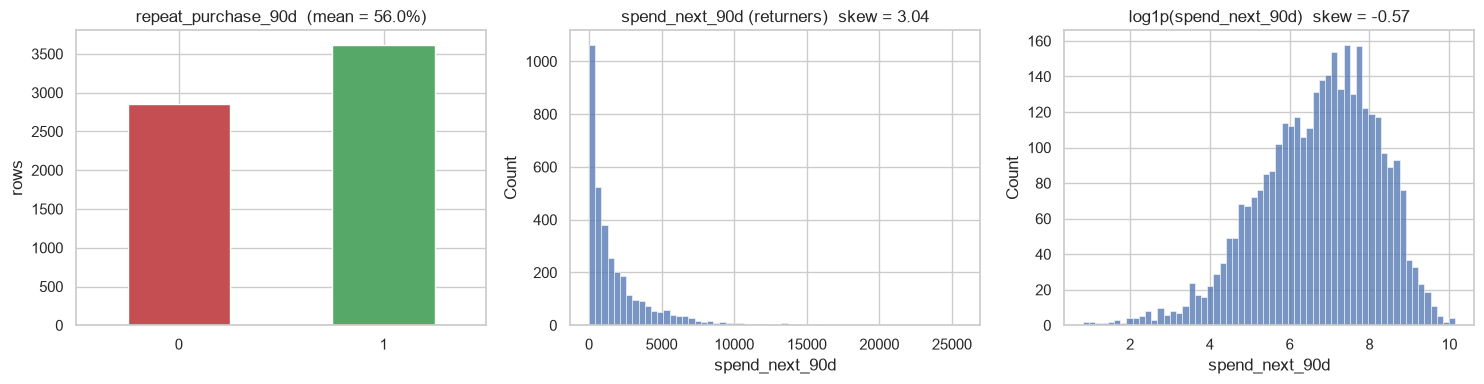

In [17]:
t = non_empty.copy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
t[CLF_TARGET].value_counts().sort_index().plot.bar(ax=axes[0], color=["#c44e52", "#55a868"])
axes[0].set(title=f"{CLF_TARGET}  (mean = {t[CLF_TARGET].mean():.1%})", xlabel="", ylabel="rows")
axes[0].tick_params(axis="x", rotation=0)

ret = t.loc[t[CLF_TARGET] == 1, REG_TARGET].dropna()
sns.histplot(ret, bins=60, ax=axes[1])
axes[1].set(title=f"{REG_TARGET} (returners)  skew = {ret.skew():.2f}")
sns.histplot(np.log1p(ret), bins=60, ax=axes[2])
axes[2].set(title=f"log1p({REG_TARGET})  skew = {np.log1p(ret).skew():.2f}")
plt.tight_layout()
plt.show()

In [18]:
print("spend_next_90d when target = 0 -> missing:", t.loc[t[CLF_TARGET] == 0, REG_TARGET].isna().all())
print("spend_next_90d missing when target = 1:", t.loc[t[CLF_TARGET] == 1, REG_TARGET].isna().sum())
print("spend_next_90d <= 0:", (t[REG_TARGET] <= 0).sum())
print(ret.describe().round(1).to_dict())

spend_next_90d when target = 0 -> missing: True
spend_next_90d missing when target = 1: 196
spend_next_90d <= 0: 0
{'count': 3425.0, 'mean': 1921.5, 'std': 2571.1, 'min': 1.3, '25%': 318.5, '50%': 985.7, '75%': 2464.6, 'max': 25654.3}


### 5.1 Are the labels consistent with the data?

In [19]:
# If the same customer has another train purchase within 90 days, the label must be 1.
s = t.assign(purchase_date=pd.to_datetime(t["purchase_date"])).sort_values(["customer_id", "purchase_date"])
days_to_next = (s.groupby("customer_id")["purchase_date"].shift(-1) - s["purchase_date"]).dt.days
print("Rows with a next train purchase <= 90 days:", (days_to_next <= 90).sum())
print("...of which labelled 0 (contradiction):", ((days_to_next <= 90) & (s[CLF_TARGET] == 0)).sum())

Rows with a next train purchase <= 90 days: 3565
...of which labelled 0 (contradiction): 0


- Classes are mildly imbalanced (~56% return). No resampling needed a priori; a threshold tuned for the chosen metric matters more.
- `spend_next_90d` is missing (= 0) for every non-returner, as expected, and **missing for 196 returners** — an error. These rows can still train the classifier but must be excluded from regression training.
- Spend is heavily right-skewed (skew ≈ 3); `log1p` makes it near-symmetric → model the log target (or use a loss that handles skew).
- Labels never contradict the purchase history in train.

## 6. Numeric features

### 6.1 Distributions

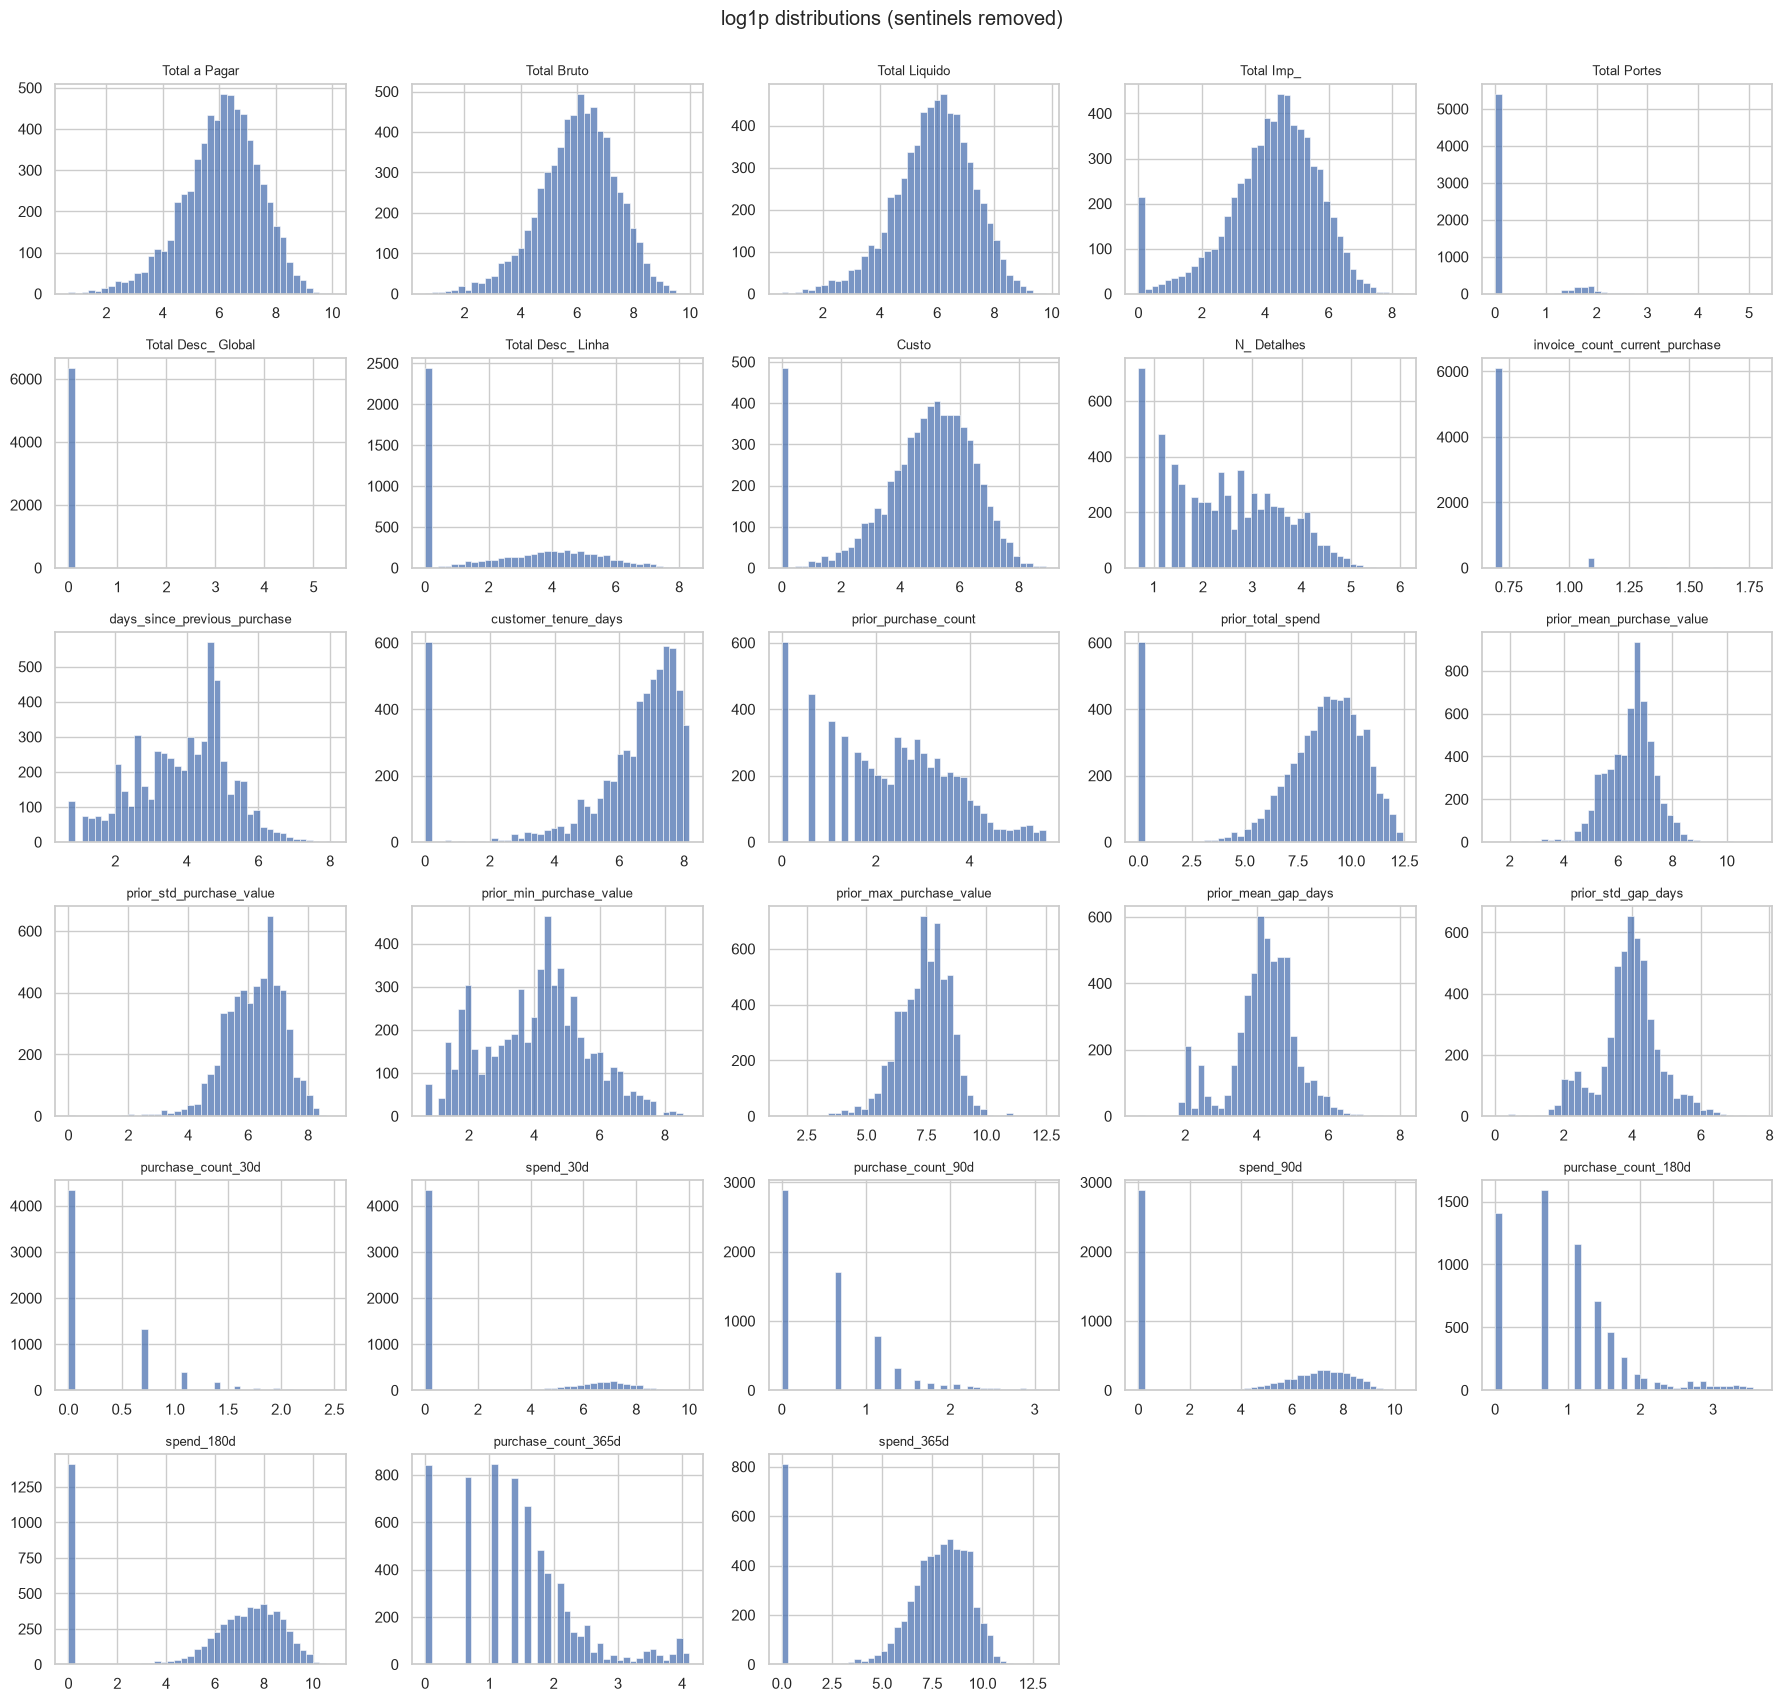

In [20]:
plot_cols = [c for c in NUM_COLS if c != "random_noise"]
clean = t.copy()
for c in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    clean.loc[clean[c] < 0, c] = np.nan
for c in ["prior_mean_purchase_value", "spend_365d"]:
    clean.loc[clean[c] >= 1e8, c] = np.nan
    clean[c] = clean[c].abs()

fig, axes = plt.subplots(6, 5, figsize=(18, 17))
for ax, c in zip(axes.flat, plot_cols):
    sns.histplot(np.log1p(clean[c].clip(lower=0)), bins=40, ax=ax)
    ax.set(title=c, xlabel="", ylabel="")
    ax.title.set_size(9)
for ax in axes.flat[len(plot_cols):]:
    ax.axis("off")
plt.suptitle("log1p distributions (sentinels removed)", y=1.0)
plt.tight_layout()
plt.show()

In [21]:
q1, q3 = clean[plot_cols].quantile(0.25), clean[plot_cols].quantile(0.75)
iqr_out = ((clean[plot_cols] > q3 + 3 * (q3 - q1)) | (clean[plot_cols] < q1 - 3 * (q3 - q1))).mean() * 100
skew = clean[plot_cols].skew()
pd.DataFrame({"skew": skew, "% beyond 3*IQR": iqr_out, "% zeros": (clean[plot_cols] == 0).mean() * 100}) \
    .sort_values("skew", ascending=False).round(1)

,skew,% beyond 3*IQR,% zeros
Total Desc_ Global,27.50,1.70,98.30
prior_max_purchase_value,21.30,1.50,0.00
prior_mean_purchase_value,21.20,2.50,0.00
Total Portes,19.50,16.30,83.70
spend_365d,18.20,3.30,12.50
prior_mean_gap_days,9.30,2.50,0.00
prior_std_gap_days,7.80,4.10,0.00
days_since_previous_purchase,6.50,2.70,0.00
invoice_count_current_purchase,6.40,5.50,0.00
Total Desc_ Linha,5.90,7.70,37.70


Almost every monetary and count variable is strongly right-skewed with many zeros (rolling windows where the customer did not buy). Extreme values are mostly genuine large customers, not errors (the impossible ones were found in section 4). → log transform / robust scaling, or tree models which are insensitive to it. Capping should be decided inside cross-validation.

### 6.2 Relationship with the targets

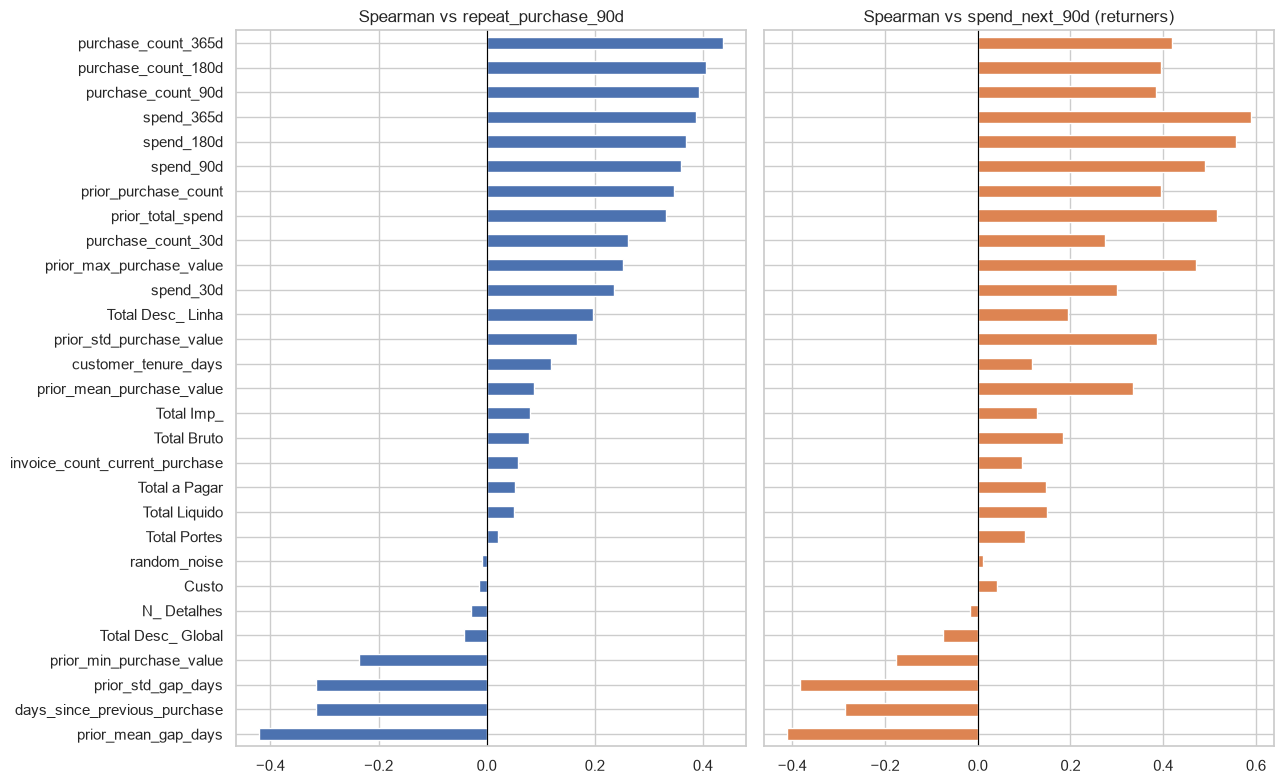

In [22]:
num = clean[NUM_COLS]
corr = pd.DataFrame({
    "spearman_vs_repeat": num.corrwith(clean[CLF_TARGET], method="spearman"),
    "spearman_vs_spend": num.corrwith(clean[REG_TARGET], method="spearman"),
}).sort_values("spearman_vs_repeat")

fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
corr["spearman_vs_repeat"].plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title("Spearman vs repeat_purchase_90d")
corr["spearman_vs_spend"].plot.barh(ax=axes[1], color="#dd8452")
axes[1].set_title("Spearman vs spend_next_90d (returners)")
for ax in axes:
    ax.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

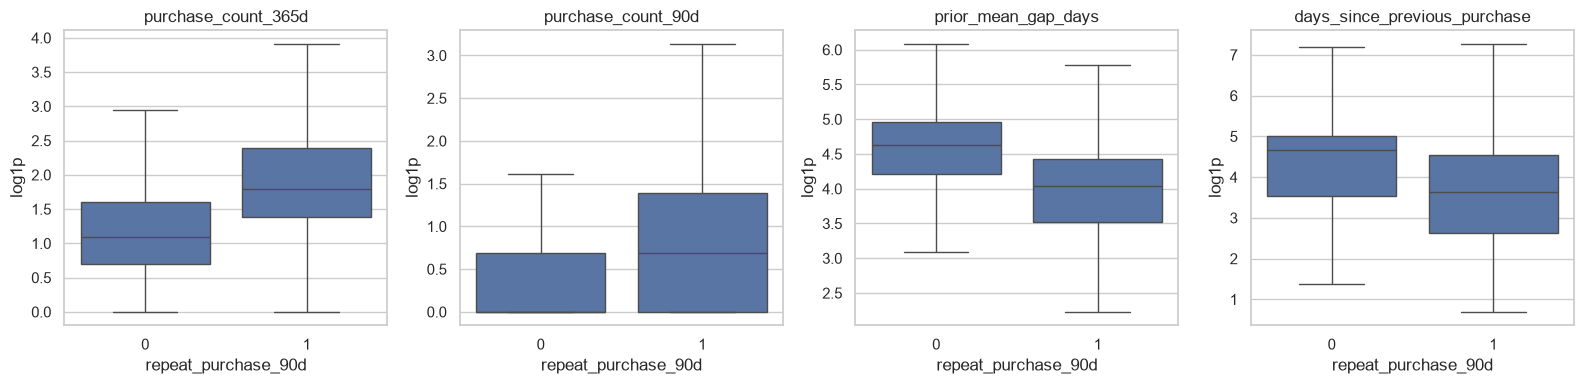

In [23]:
top = ["purchase_count_365d", "purchase_count_90d", "prior_mean_gap_days", "days_since_previous_purchase"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, top):
    sns.boxplot(data=clean, x=CLF_TARGET, y=np.log1p(clean[c]), ax=ax, showfliers=False)
    ax.set(title=c, ylabel="log1p")
plt.tight_layout()
plt.show()

- **Purchase frequency is the strongest signal**: rolling counts (90/180/365 days) and prior purchase count increase return probability; long gaps between purchases (`prior_mean_gap_days`, `days_since_previous_purchase`) decrease it.
- **The size of the current purchase barely matters** for returning (|ρ| < 0.1 for all current-transaction totals).
- For spend, past spend (`spend_365d`, `spend_180d`, `prior_total_spend`) is the strongest predictor.

### 6.3 Redundancy between features

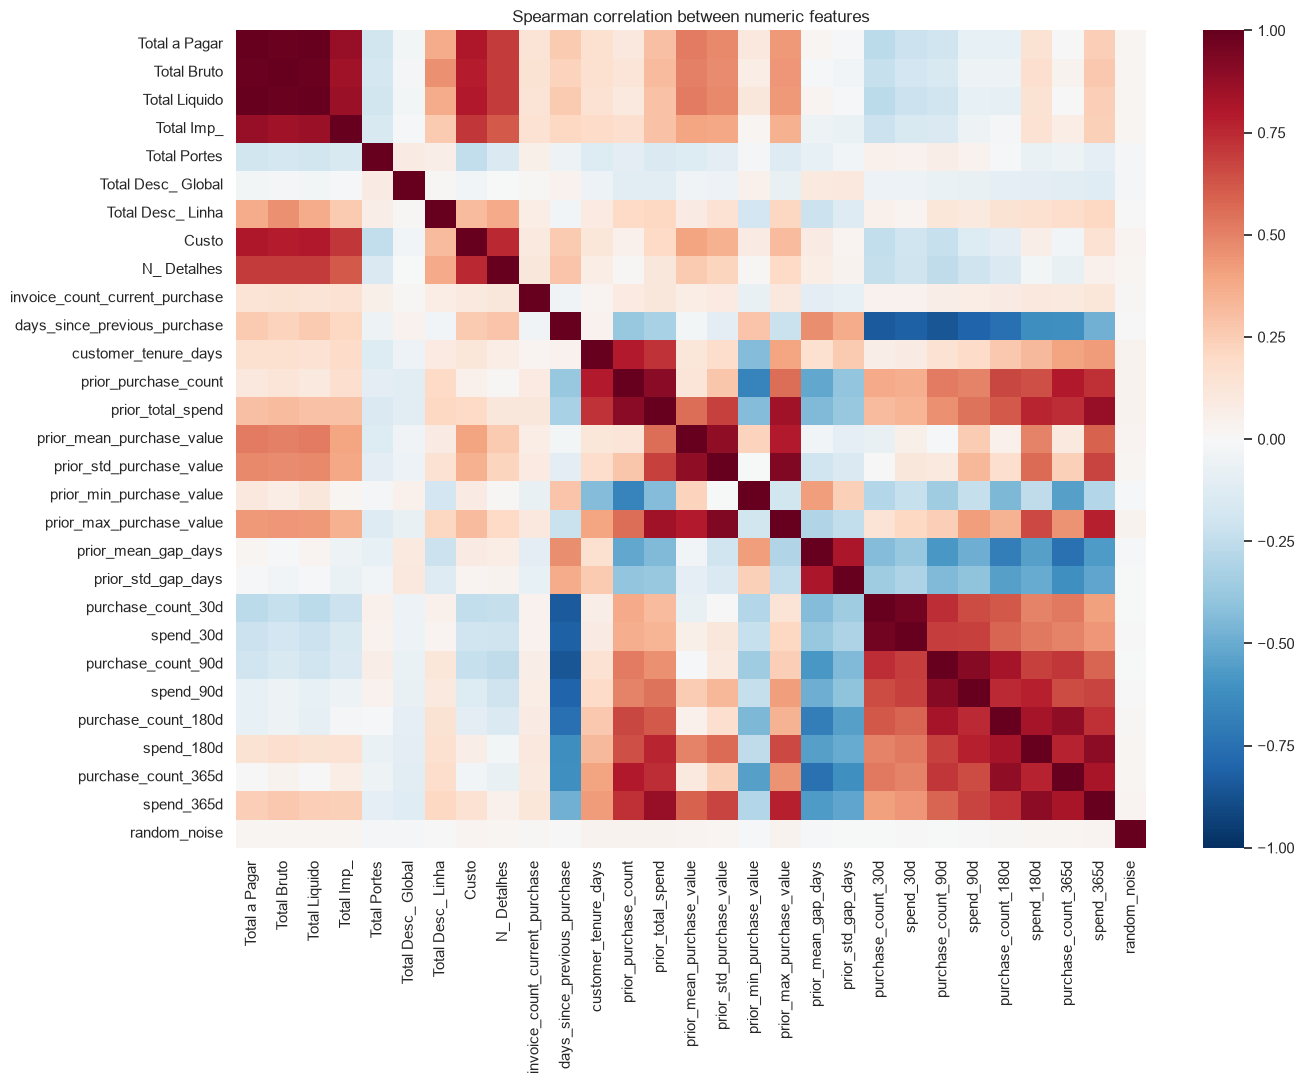

In [24]:
plt.figure(figsize=(14, 11))
sns.heatmap(num.corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.title("Spearman correlation between numeric features")
plt.tight_layout()
plt.show()

In [25]:
c = num.corr(method="spearman").abs()
pairs = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
pairs[pairs > 0.9].to_frame("|rho|")

,,|rho|
Total a Pagar,Total Liquido,1.00
Total Bruto,Total Liquido,0.99
Total a Pagar,Total Bruto,0.99
purchase_count_30d,spend_30d,0.97
prior_std_purchase_value,prior_max_purchase_value,0.92
purchase_count_90d,spend_90d,0.91
prior_purchase_count,prior_total_spend,0.90


The monetary columns of the current purchase (`Total Bruto`, `Liquido`, `a Pagar`, `Imp_`, `Custo`) are near-duplicates of each other, and the rolling spend/count windows are highly correlated with their neighbours. Feature selection should remove this redundancy (keep one representative, or replace by ratios such as discount rate, margin, trend `spend_90d / spend_365d`).

## 7. Categorical features

In [26]:
card = pd.DataFrame({
    "levels_train": t[CAT_COLS].nunique(),
    "levels_test": test[CAT_COLS].nunique(),
    "top_level_share_%": t[CAT_COLS].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100),
    "levels_<30_rows": t[CAT_COLS].apply(lambda s: (s.value_counts() < 30).sum()),
    "test_levels_unseen_in_train": [len(set(test[c].dropna()) - set(t[c].dropna())) for c in CAT_COLS],
})
card.round(1)

,levels_train,levels_test,top_level_share_%,levels_<30_rows,test_levels_unseen_in_train
payment_type,9,11,72.80,4,3
salesperson,9,3,64.60,3,0
commercial_zone,5,5,96.80,2,2
transport_method,80,29,17.80,51,2
warehouse,2,2,99.70,1,1
document_series,3,1,42.30,0,0


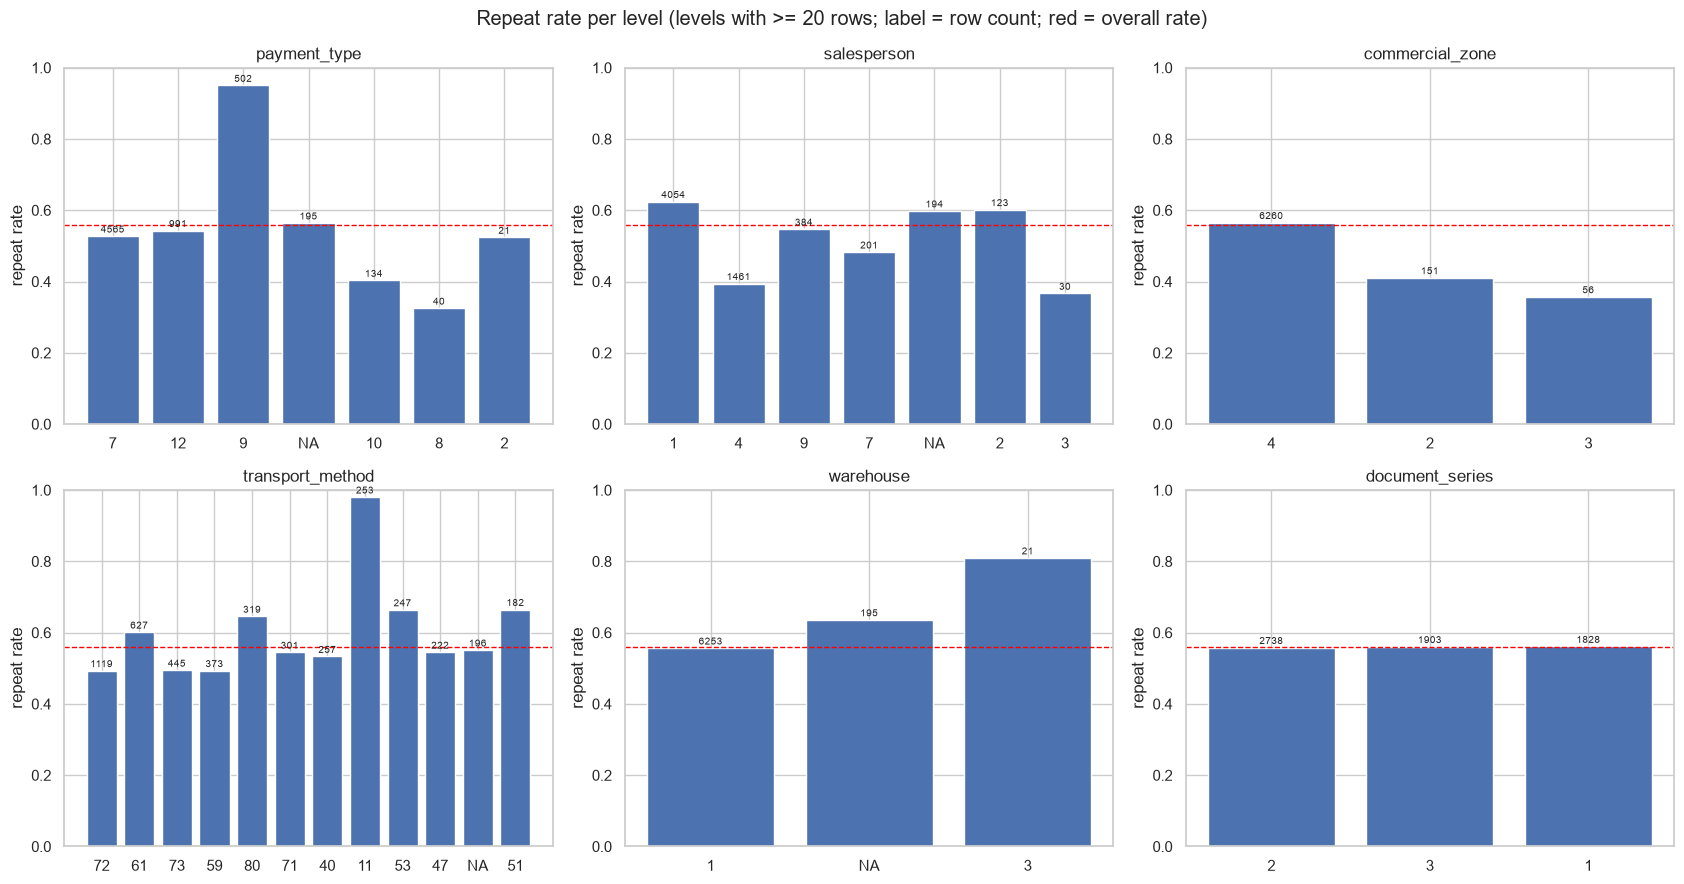

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
base = t[CLF_TARGET].mean()
for ax, c in zip(axes.flat, CAT_COLS):
    g = t.groupby(t[c].fillna("MISSING"))[CLF_TARGET].agg(["mean", "size"])
    g = g[g["size"] >= 20].sort_values("size", ascending=False).head(12)
    g.index = [str(i).split()[-1] if i != "MISSING" else "NA" for i in g.index]
    ax.bar(g.index, g["mean"], color="#4c72b0")
    ax.axhline(base, color="red", ls="--", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.01, n, ha="center", fontsize=7)
    ax.set(title=c, ylim=(0, 1), ylabel="repeat rate")
plt.suptitle("Repeat rate per level (levels with >= 20 rows; label = row count; red = overall rate)")
plt.tight_layout()
plt.show()

- `warehouse` and `commercial_zone` are almost constant (>95% one level) → little information.
- `transport_method` has 80 levels, many rare → group rare levels or use target / frequency encoding (fitted inside CV).
- `payment_type` and `transport_method` contain very strong levels: payment type 9 (502 rows) and transport method 11 (253 rows) have a repeat rate of ~95–98%. `salesperson` also varies (salesperson 4: ~39% vs salesperson 1: ~62%).
- `document_series` has the same repeat rate in all three levels → no signal.
- **Test contains levels never seen in train** (3 in `payment_type`, 2 in `commercial_zone`, 2 in `transport_method`, 1 in `warehouse`) → the encoder must handle unknown levels (`handle_unknown="ignore"` / map to "other"). The client interface needs the same.

## 8. Time

train: 2015-07-11 -> 2025-02-15
test:  2025-05-24 -> 2026-10-06
gap between train end and test start: 98 days


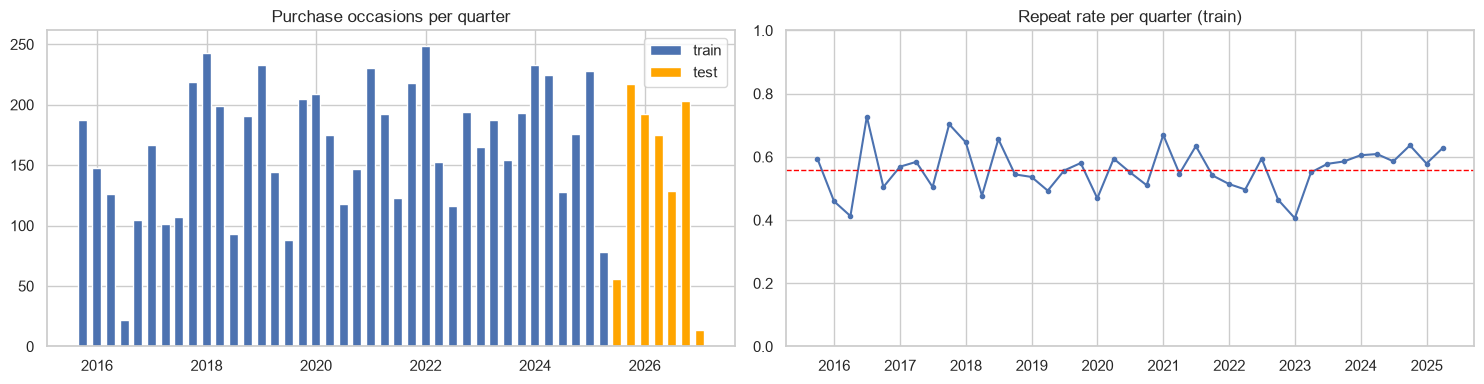

In [28]:
t["date"] = pd.to_datetime(t["purchase_date"])
te_dates = pd.to_datetime(test["purchase_date"])
print("train:", t["date"].min().date(), "->", t["date"].max().date())
print("test: ", te_dates.min().date(), "->", te_dates.max().date())
print("gap between train end and test start:", (te_dates.min() - t["date"].max()).days, "days")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
monthly = t.set_index("date").resample("QE")[CLF_TARGET].agg(["size", "mean"])
axes[0].bar(monthly.index, monthly["size"], width=60, label="train")
tq = te_dates.dt.to_period("Q").dt.to_timestamp("Q").value_counts().sort_index()
axes[0].bar(tq.index, tq.values, width=60, color="orange", label="test")
axes[0].set(title="Purchase occasions per quarter")
axes[0].legend()
axes[1].plot(monthly.index, monthly["mean"], marker="o", ms=3)
axes[1].axhline(t[CLF_TARGET].mean(), color="red", ls="--", lw=1)
axes[1].set(title="Repeat rate per quarter (train)", ylim=(0, 1))
plt.tight_layout()
plt.show()

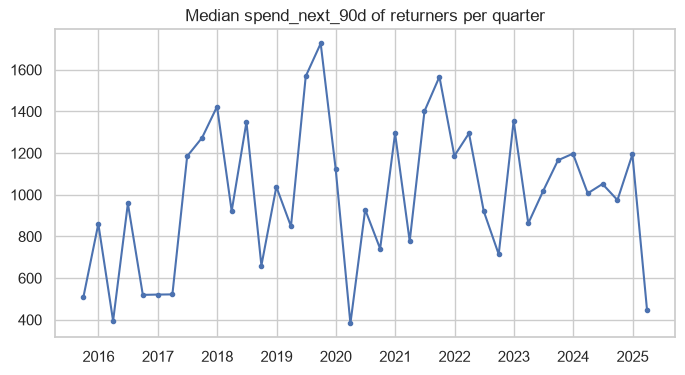

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t.set_index("date").resample("QE")[REG_TARGET].median(), marker="o", ms=3)
ax.set(title="Median spend_next_90d of returners per quarter")
plt.show()

- Train covers 2015-07 → 2025-02 and test 2025-05 → 2026-10: **test is strictly in the future**, with a ~3-month gap (the 90-day label window).
- Repeat rate fluctuates between quarters with no strong trend.
- → Validation must respect time: train on older rows, validate on the most recent ones (hold-out or `TimeSeriesSplit`). A random K-fold would leak future information of the same customer and overestimate performance.

## 9. `random_noise`

mean -0.022, std 1.001, normality p-value 0.155
Pearson vs repeat -0.0120  |  Spearman vs spend 0.0111
Mutual information: random_noise 0.0049  vs  purchase_count_365d 0.1211
Point-biserial t-test p-value: 0.335


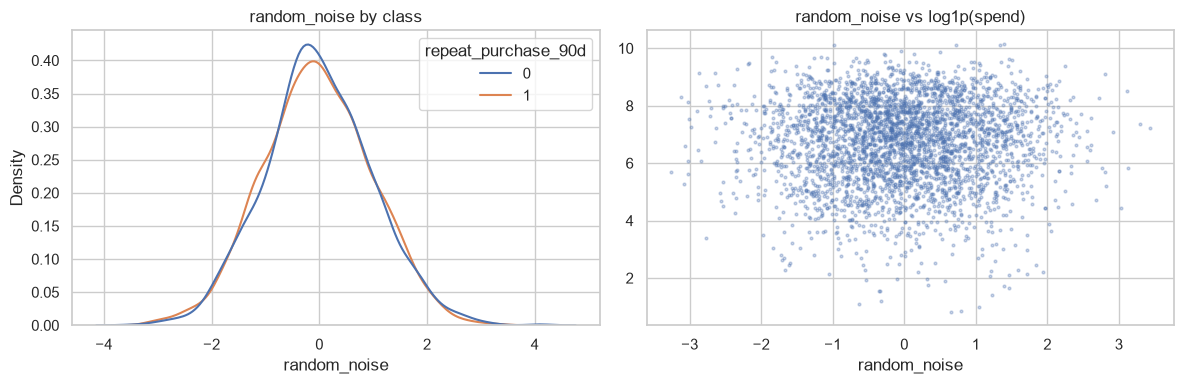

In [30]:
n = t["random_noise"]
print(f"mean {n.mean():.3f}, std {n.std():.3f}, normality p-value {stats.normaltest(n).pvalue:.3f}")
print(f"Pearson vs repeat {np.corrcoef(n, t[CLF_TARGET])[0, 1]:.4f}  |  "
      f"Spearman vs spend {n.corr(t[REG_TARGET], method='spearman'):.4f}")
mi = mutual_info_classif(t[["random_noise", "purchase_count_365d"]], t[CLF_TARGET], random_state=0)
print(f"Mutual information: random_noise {mi[0]:.4f}  vs  purchase_count_365d {mi[1]:.4f}")
print("Point-biserial t-test p-value:", round(stats.ttest_ind(n[t[CLF_TARGET] == 1], n[t[CLF_TARGET] == 0]).pvalue, 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=t, x="random_noise", hue=CLF_TARGET, common_norm=False, ax=axes[0])
axes[0].set_title("random_noise by class")
axes[1].scatter(n, np.log1p(t[REG_TARGET]), s=4, alpha=0.3)
axes[1].set(title="random_noise vs log1p(spend)", xlabel="random_noise")
plt.tight_layout()
plt.show()

`random_noise` follows a standard normal distribution and has no relationship with either target (correlation ≈ 0, MI ≈ 0, identical class distributions). It is pure noise → **drop it**. It is also a useful sanity check: any feature-selection method that keeps it is not working properly.

## 10. `clientes.csv`

In [31]:
pd.DataFrame({"missing_%": clients.isna().mean() * 100, "n_unique": clients.nunique()}).round(1)

,missing_%,n_unique
customer_id,0.00,1143
country_or_region,0.00,11
commercial_region,10.00,37
island,50.60,10
municipality,13.90,183
city,47.80,417
postal_area,6.20,271
postal_code,14.90,828
street,52.30,511
address,0.50,1120


customer_id unique: True
Train customers covered: 1.0 | Test customers covered: 1.0
customer_since_year after the purchase year: 0
customer_since_year after first purchase year: 0


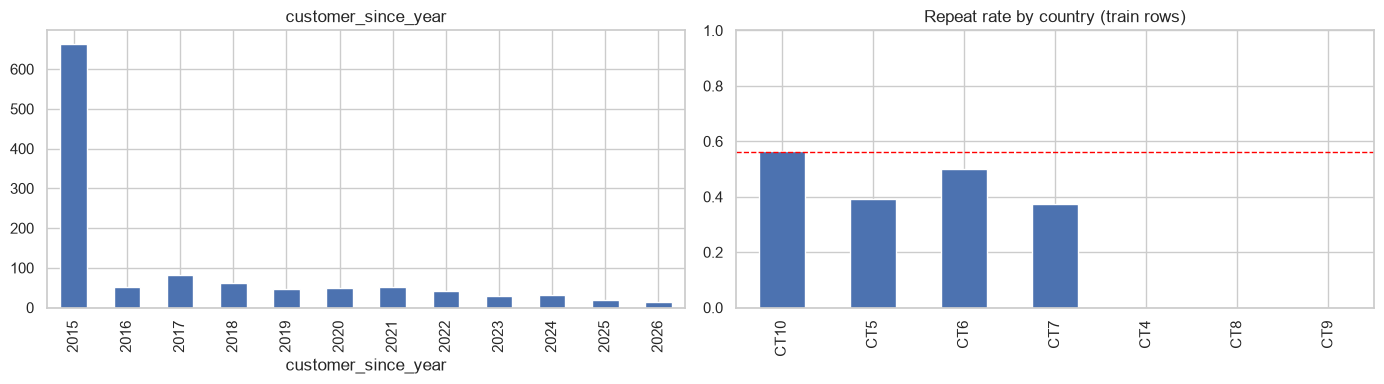

,mean,size
CT10,0.57,6256
CT5,0.39,194
CT6,0.50,8
CT7,0.38,8
CT4,0.00,1
CT8,0.00,1
CT9,0.00,1


In [32]:
print("customer_id unique:", clients["customer_id"].is_unique)
print("Train customers covered:", train["customer_id"].isin(clients["customer_id"]).mean(),
      "| Test customers covered:", test["customer_id"].isin(clients["customer_id"]).mean())

m = t.merge(clients[["customer_id", "customer_since_year", "country_or_region"]], on="customer_id")
first_purchase_year = (m["date"] - pd.to_timedelta(m["customer_tenure_days"], unit="D")).dt.year
print("customer_since_year after the purchase year:", (m["customer_since_year"] > m["date"].dt.year).sum())
print("customer_since_year after first purchase year:", (m["customer_since_year"] > first_purchase_year).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
clients["customer_since_year"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("customer_since_year")
g = m.groupby("country_or_region")[CLF_TARGET].agg(["mean", "size"]).sort_values("size", ascending=False)
g.index = [i.split(":")[0].replace("Country ", "") for i in g.index]
g["mean"].plot.bar(ax=axes[1])
axes[1].axhline(t[CLF_TARGET].mean(), color="red", ls="--", lw=1)
axes[1].set(title="Repeat rate by country (train rows)", ylim=(0, 1))
plt.tight_layout()
plt.show()
g

- One row per customer, every train and test customer is covered.
- `customer_type` is 100% empty; `company_name` and `address` are unique per customer (identifiers) → drop.
- `island`, `city`, `street` are ~50% missing; `postal_code`, `municipality` have hundreds of levels → low value, high overfitting risk.
- Usable: `commercial_region` (37 levels), `customer_since_year`, and `country_or_region` (97% of rows are one country, but the second one, CT5, has a clearly lower repeat rate). `customer_since_year` is never after the purchase date, so it is safe to use. 2015 is overrepresented because it is the start of the data (older customers are capped at 2015).

## 11. Train vs test

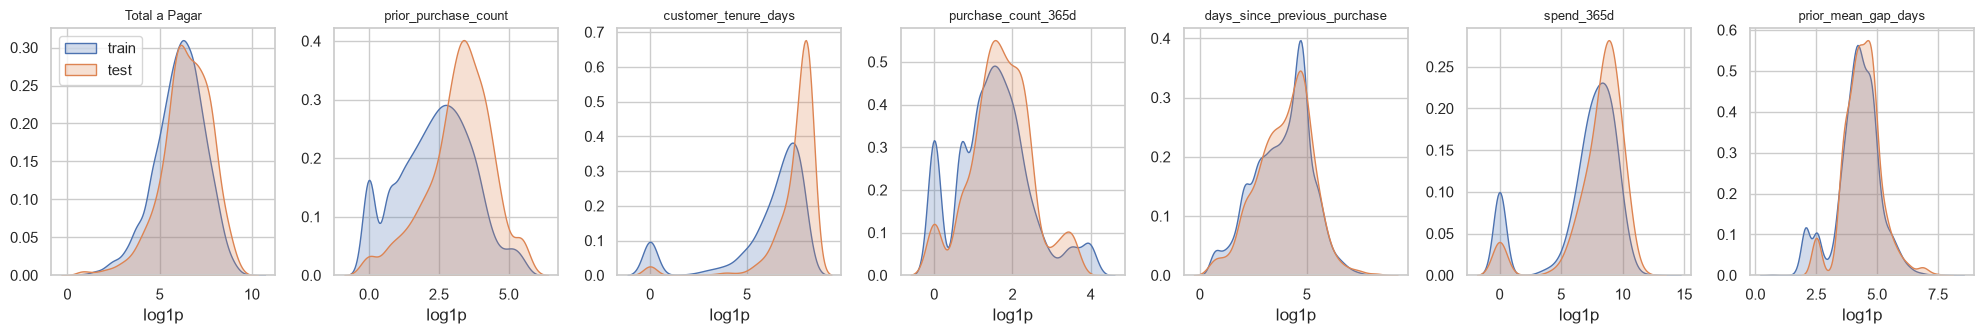

,feature,train_median,test_median,KS_stat
0,Total a Pagar,476.74,663.88,0.13
1,prior_purchase_count,11.00,28.00,0.31
2,customer_tenure_days,918.00,"2,662.00",0.46
3,purchase_count_365d,3.00,4.00,0.13
4,days_since_previous_purchase,57.00,60.50,0.04
5,spend_365d,"2,427.06","5,423.65",0.21
6,prior_mean_gap_days,68.61,78.93,0.10


In [33]:
compare = ["Total a Pagar", "prior_purchase_count", "customer_tenure_days", "purchase_count_365d",
           "days_since_previous_purchase", "spend_365d", "prior_mean_gap_days"]
fig, axes = plt.subplots(1, len(compare), figsize=(20, 3.5))
rows = []
for ax, c in zip(axes, compare):
    a = clean[c].dropna()
    b = test[c].where(test[c].between(0, 1e8)).dropna()
    sns.kdeplot(np.log1p(a), ax=ax, label="train", fill=True)
    sns.kdeplot(np.log1p(b), ax=ax, label="test", fill=True)
    ax.set(title=c, xlabel="log1p", ylabel="")
    ax.title.set_size(9)
    rows.append({"feature": c, "train_median": a.median(), "test_median": b.median(),
                 "KS_stat": stats.ks_2samp(a, b).statistic})
axes[0].legend()
plt.tight_layout()
plt.show()
pd.DataFrame(rows).round(2)

In [34]:
new_cust = ~test["customer_id"].isin(train["customer_id"])
print(f"Test customers: {test['customer_id'].nunique()}, of which new: {test.loc[new_cust, 'customer_id'].nunique()}")
print(f"Test rows of new customers: {new_cust.sum()} | first-ever purchase (prior_purchase_count == 0): {(test['prior_purchase_count'] == 0).sum()}")

Test customers: 206, of which new: 22
Test rows of new customers: 54 | first-ever purchase (prior_purchase_count == 0): 22


Test customers are **older and more loyal** than the average train row (median tenure 2,662 vs 918 days, median prior purchases 28 vs 11). This is natural — test is later in time, so returning customers have accumulated more history — but it means the model will often be used in the high-history region. A time-based validation split reproduces this shift. Most test customers are known from train (184 / 206), 22 are new.

## 12. Conclusions and cleaning plan

### Data errors found

| # | Problem | Columns | Train | Test | Fix |
|---|---|---|---|---|---|
| 1 | Fully empty rows (incl. all duplicates) | all features | 65 | 0 | Drop |
| 2 | Random missing values (~3%) | 4 categoricals, `spend_365d`, `days_since_previous_purchase`, `prior_mean_purchase_value` | ~195 each | ~30 each | Recompute `prior_mean = total / count`; otherwise impute in pipeline |
| 3 | `-4` placeholder | `days_since_previous_purchase`, `prior_mean_gap_days` | 16 + 16 | 2 + 2 | Set to NaN → impute |
| 4 | `1e9` placeholder | `prior_mean_purchase_value`, `spend_365d` | 16 + 15 | 2 + 2 | Set to NaN → recompute / impute |
| 5 | Sign flip | `prior_mean_purchase_value`, `spend_365d` | 16 + 15 | 2 + 2 | Absolute value |
| 6 | Inflated values (×1.5–25, impossible vs. total history) | `spend_365d`, `prior_max_purchase_value`, `prior_mean_purchase_value` | 39 + 45 + 46 | 7 + 6 + 7 | Set to NaN → recompute / impute |
| 7 | Missing regression target for returners | `spend_next_90d` | 196 | – | Exclude from regression training only |
| 8 | Useless columns | `random_noise`, `customer_type`, `company_name`, `address` | | | Drop |

Not errors (kept): missing history for first/second purchases (structural), `Total a Pagar` slightly below `Liquido + Imp + Portes`, `Custo == 0`, large but consistent monetary values.

The same errors appear in test, so **every fix must be part of the prediction pipeline**, not a one-off edit of the training file.

### Key insights for modelling

1. **Frequency drives returning.** Rolling purchase counts and short purchase gaps are the strongest predictors; the size of the current purchase is almost irrelevant.
2. **Past spend drives future spend.** `spend_365d`, `spend_180d` and `prior_total_spend` correlate ~0.5–0.6 with `spend_next_90d`.
3. **Spend is heavily skewed** → model `log1p(spend)`.
4. **Test is in the future and contains more loyal customers** → time-based validation, never random K-fold.
5. **Strong redundancy** among current-purchase totals and rolling windows → feature selection / ratio features.
6. **Categoricals:** payment type 9 and transport method 11 are near-certain returners; `document_series` carries no signal; `warehouse` and `commercial_zone` nearly constant; `transport_method` needs rare-level grouping; test has unseen levels → encoders must handle unknown categories.
7. **First-time buyers** (no history) exist in train (603 rows) and test (22) → indicator feature, and the client interface must handle them.
8. **`random_noise` is noise** → drop; use as a sanity check for feature selection.